# Librerias y constantes

In [132]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.special import zeta
from scipy.integrate import solve_ivp, quad

OB = .27
T0 = 2.35E-10 #MeV
ME = .5 #MeV
MP = 938.27208943 #MeV
MH = 938.78 #MeV
B = 13.6 / 1E6 #MeV
ALPHA = 1/137
H0 = 1.49E-39 #MeV
H1 = np.sqrt(H0**2 * OB * (B/T0)**3)

# Ejercicios

## Item $(b)$

### Grafico de $X(T)$

/tmp/ipykernel_11114/4106012946.py:2: RuntimeWarning: overflow encountered in exp
  a = lambda T: 3.84 * eta_b(T) * (T/ME)**(3/2) * np.exp(B/T)
/tmp/ipykernel_11114/4106012946.py:3: RuntimeWarning: invalid value encountered in divide
  X_p = lambda T: (-1 + np.sqrt(1 + (4*a(T)))) / (2 * a(T))
/tmp/ipykernel_11114/4106012946.py:4: RuntimeWarning: invalid value encountered in divide
  X_m = lambda T: (-1 - np.sqrt(1 + (4*a(T)))) / (2 * a(T))


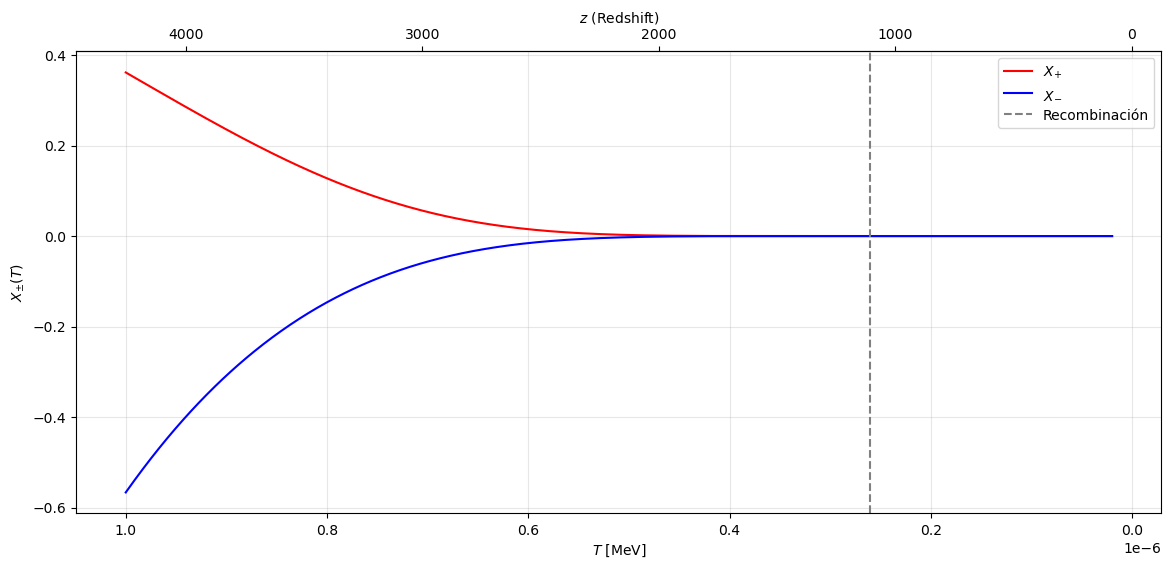

In [133]:
eta_b = lambda T: 2.68E-8 * OB * (T / T0)**3
a = lambda T: 3.84 * eta_b(T) * (T/ME)**(3/2) * np.exp(B/T)
X_p = lambda T: (-1 + np.sqrt(1 + (4*a(T)))) / (2 * a(T))
X_m = lambda T: (-1 - np.sqrt(1 + (4*a(T)))) / (2 * a(T))
T_R = 2.6E-7 #MeV

T = np.linspace(1E-8, 1E-6, 1_000) #MeV

def T2z(T):
    return T/T0 - 1

def z2T(z):
    return T0 * (1 + z)

fig, ax = plt.subplots(figsize = (14, 6))

ax.plot(T, X_p(T), color = 'red', label = r'$X_{+}$')
ax.plot(T, X_m(T), color = 'blue', label = r'$X_{-}$')
ax.axvline(T_R, linestyle = '--', color = 'gray', label = 'Recombinación')

secax = ax.secondary_xaxis('top', functions = (T2z, z2T))
secax.set_xlabel(r'$z$ (Redshift)')

ax.set(ylabel = r'$X_{\pm}(T)$', xlabel = r'$T$ [MeV]')
ax.xaxis.set_inverted(True)
ax.grid(alpha = .3), ax.legend()

fig.savefig('Xpm.png', bbox_inches = 'tight')

### Encontrar $T_R$

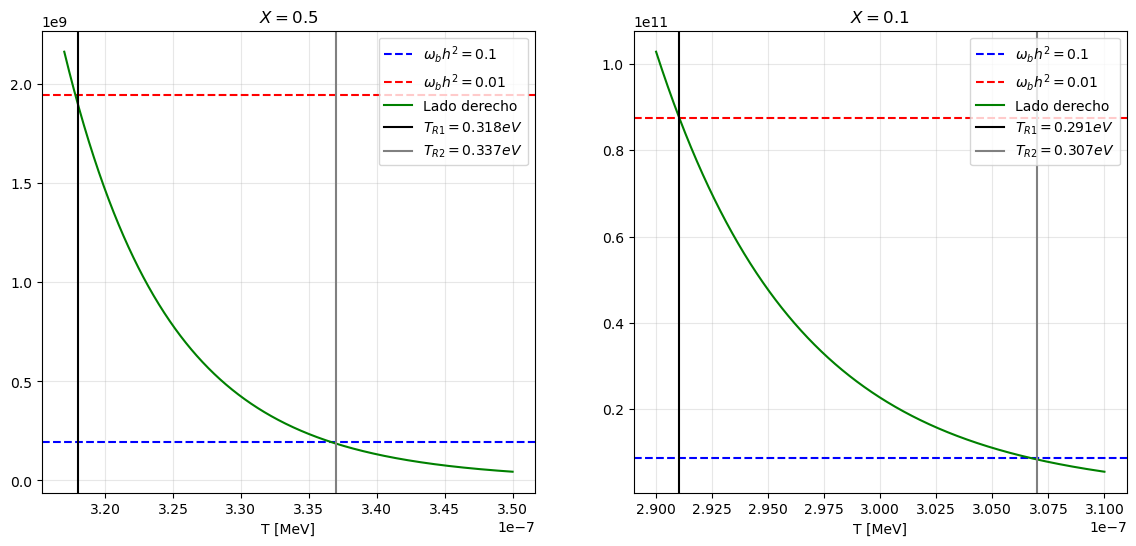

In [134]:
def izq(y, x):
    CTE = (3.84 * 2.68E-8)**(-1)
    pfactor = (1 - x)/x**2
    postfactor = y**(-1)
    return pfactor * CTE * postfactor

def der(T):
    return (T/ME)**(3/2) * np.exp(B/T)

fig, axs = plt.subplots(1, 2, figsize = (14, 6))

# Gráfico para X = .5
T_1 = np.linspace(.317E-6, .35E-6, 1000)
axs[0].axhline(izq(y = .1, x = .5), linestyle = '--',
               color = 'blue', label = r'$\omega_b h^2 = 0.1$')
axs[0].axhline(izq(y = .01, x = .5), linestyle = '--',
               color = 'red', label = r'$\omega_b h^2 = 0.01$')
axs[0].plot(T_1, der(T_1), color = 'green', label = 'Lado derecho')

axs[0].axvline(.318E-6, linestyle = '-', color = 'black', 
               label = r'$T_{R1} = 0.318 eV$')

axs[0].axvline(.337E-6, linestyle = '-', color = 'gray', 
               label = r'$T_{R2} = 0.337 eV$')
eta_b
axs[0].set(xlabel = 'T [MeV]', title = r'$X = 0.5$'), axs[0].grid(alpha = .3)
axs[0].legend(loc = 'upper right')

# Gráfico para X = .1
T_2 = np.linspace(.29E-6, .31E-6, 1000)
axs[1].axhline(izq(y = .1, x = .1), linestyle = '--',
               color = 'blue', label = r'$\omega_b h^2 = 0.1$')
axs[1].axhline(izq(y = .01, x = .1), linestyle = '--',
               color = 'red', label = r'$\omega_b h^2 = 0.01$')
axs[1].plot(T_2, der(T_2), color = 'green', label = 'Lado derecho')

axs[1].axvline(.291E-6, linestyle = '-', color = 'black', 
               label = r'$T_{R1} = 0.291 eV$')

axs[1].axvline(.307E-6, linestyle = '-', color = 'gray', 
               label = r'$T_{R2} = 0.307 eV$')

axs[1].set(xlabel = 'T [MeV]', title = r'$X = 0.1$'), axs[1].grid(alpha = .3)
axs[1].legend(loc = 'upper right')

fig.savefig('estimacion-recombinacion.png', bbox_inches = 'tight')


## Item $(c)$

Estudio los factores de la ecuación diferencial

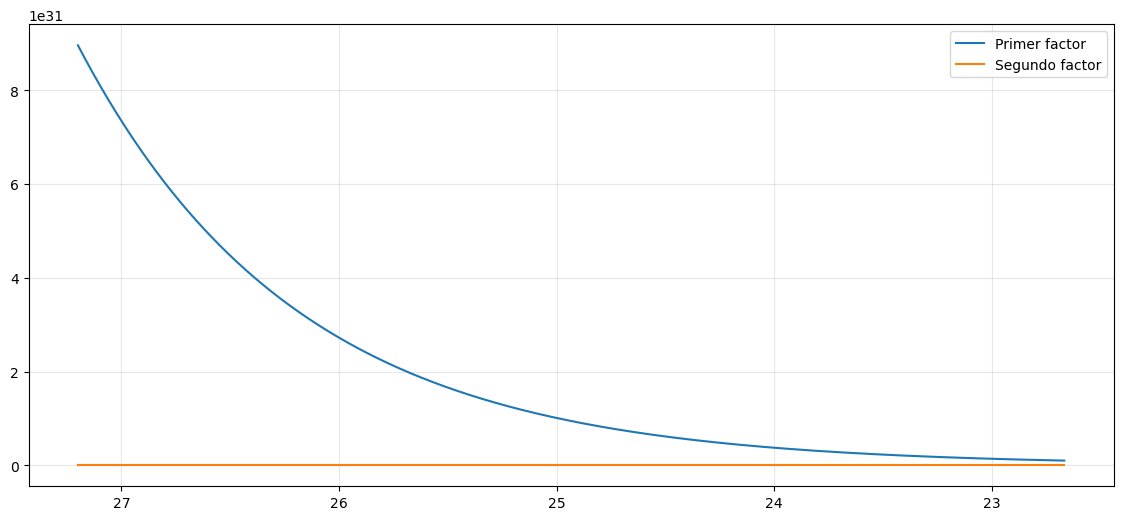

In [167]:
def ffactor(x):
    eta = 2.68E-8 * OB * B**3 / T0**3 * x**(-3)
    thermal = 9.78 * (ALPHA / ME)**2 * np.sqrt(x) * np.log(x)

    gfactor = thermal * np.sqrt(x) / H1
    first_factor = ( ME * B / 2 / np.pi )**(3/2) * np.exp(x) / x**(3/2)
    return gfactor*first_factor

def sfactor(x):
    eta = 2.68E-8 * OB * B**3 / T0**3 * x**(-3)
    thermal = 9.78 * (ALPHA / ME)**2 * np.sqrt(x) * np.log(x)

    gfactor = thermal * np.sqrt(x) / H1
    second_factor = eta * (2 * zeta(3) * B**3 / np.pi**2) / x**3
    return gfactor * second_factor

# Condiciones iniciales y final
T_0, T_F = .6E-6, .5E-6 #MeV
X_0 = X_p(T_0)

x_0, x_F = B / T_0, B / T_F
xs = np.linspace(x_0, x_F, 1_000)

# Gráfico
fig, ax = plt.subplots(figsize = (14, 6))

ax.plot(xs, ffactor(xs), label = 'Primer factor')
ax.plot(xs, sfactor(xs), label = 'Segundo factor')

ax.xaxis.set_inverted(True)
ax.grid(alpha = .3), ax.legend()
fig.savefig('Fallo.png', bbox_inches = 'tight')


In [166]:
def dXdx(x, X):
    eta = 2.68E-8 * OB * B**3 / T0**3 * x**(-3)
    thermal = 9.78 * (ALPHA / ME)**2 * np.sqrt(x) * np.log(x)

    gfactor = thermal * np.sqrt(x) / H1
    ffactor = ( ME * B / 2 / np.pi )**(3/2) * np.exp(x) / x**(3/2) * (1 - X)
    sfactor = eta * (2 * zeta(3) * B**3 / np.pi**2) / x**3 * X**2

    return gfactor * (ffactor - sfactor)

# Condiciones iniciales y final
T_0, T_F = .6E-6, .5E-6 #MeV
X_0 = X_p(T_0)

x_0, x_F = B / T_0, B / T_F

# Solver
sol = solve_ivp(dXdx, [x_0, x_F], np.array([X_0]), dense_output = True)
sol.sol(xs)

/tmp/ipykernel_11114/1322244556.py:7: RuntimeWarning: overflow encountered in square
  sfactor = eta * (2 * zeta(3) * B**3 / np.pi**2) / x**3 * X**2
/tmp/ipykernel_11114/1322244556.py:9: RuntimeWarning: invalid value encountered in subtract
  return gfactor * (ffactor - sfactor)


IndexError: list index out of range

Comparo en un gráfico con la solución en equilibrio

In [156]:
Temps = np.linspace(T_0, T_F, 1_000) #MeV
xs = B / Temps
#fig, ax = plt.subplots(figsize = (14, 6))

#ax.plot(Temps, sol.sol(xs)[0])
sol.sol(xs)[0]

IndexError: list index out of range